# 02 · A detector built on how predictable a text is
**Report sections:** Model comparison (Q1), Generalization (Q4), Open-ended improvement (Q5)

**Idea.** The team's models learn *which words* go with AI text, and notebook `01` showed that this weakens on topics
the model has not seen. Here we ignore the words themselves. A small pretrained language model (GPT-2) reads each text
and we measure how *expected* every token was. AI text tends to follow the model's expectations more evenly than human
text does. A small classifier is trained on 24 such numbers, and then blended with Allen's SVM.

**Rules kept.** GPT-2 runs on the laptop (no API), its weights are not trained here, labels come only from `train.csv`,
and all numbers use the team's shared 2,000-row validation set. Blend weights are chosen on training rows only.

**Findings (numbers are in the tables below).**
- **The language-model classifier barely changes on unseen topics.** Boosted trees on the 24 features: validation 0.979,
  unseen domain 0.976. Allen's tuned SVM: 0.979 and 0.933.
- **The two models disagree in a useful way** (rank correlation 0.76 on validation, 0.67 on test), so blending helps.
- **The blend is better than either model on all four numbers.** SVM + language-model classifier, weight 0.6:
  validation 0.993, unseen domain + layout removed 0.987 (SVM alone: 0.979 and 0.933).
- **Not yet known:** the Kaggle score. Our stress test changes the topic, but the real test set also has new AI
  generators and edited AI text, and predictability features could behave differently there.

In [1]:
# --- setup: make `src/` and this folder importable from anywhere ---
import sys, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks" / "joling"))
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from src.config import SEED, set_seed, RESULTS_DIR
from src.data import get_split, load_test
from src.models import make_model
from src.features import has_blank_line_breaks
from src.evaluate import (auroc, predict_proba1, cross_val_auroc, log_result, savefig,
                          save_predictions, write_submission)

from domain_eval import TopicDomains, domain_stress_test, mean_auroc_by_domain
from lm_features import FEATURES, load_cached
from lm_model import lm_logreg, lm_boost, blend, blend_by_domain
from plots import plot_stress_summary, plot_feature_by_class, plot_weight_curve

set_seed(SEED)
pd.set_option("display.width", 200)

## Data
The shared split, plus the cached language-model features. The cache was made once with
`python notebooks/joling/lm_features.py` (about 30 minutes on a laptop) and is stored in
`results/joling_lm_features_gpt2.csv`, so this notebook does not need to run GPT-2 again.

In [3]:
train_df, val_df = get_split()
test_df = load_test()
y_tr, y_va = train_df["label"].to_numpy(), val_df["label"].to_numpy()

feats = load_cached()                     # one row per text id, for train + unlabeled + test
print(f"cached features: {feats.shape[0]:,} texts x {len(FEATURES)} features;  missing values: {int(feats[FEATURES].isna().sum().sum())}")

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)
split: train=8000 (AI=0.500)  val=2000 (AI=0.500)  quick=False clean=True


[test] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)
cached features: 16,000 texts x 24 features;  missing values: 0


## Step 1 · What do the features look like?
Each feature on its own, scored on the validation set. An AUROC far from 0.5 in either direction is useful
(below 0.5 just means "higher value = more human").

- `ll_*`: log-probability GPT-2 gave to the tokens that were really written (mean, spread, percentiles).
- `ent_*`: how unsure GPT-2 was before each token. `curvature`, `z_*`: surprise compared with what GPT-2 itself expected.
- `top1` ... `beyond1000`, `log_rank_mean`: where the real token ranked among GPT-2's guesses.
- `xent_mean`, `binoculars`: the same text seen through a second model (distilgpt2) as a reference point.

In [4]:
F_va = feats.loc[val_df["id"], FEATURES]
single = pd.DataFrame({"val_auroc": {f: auroc(y_va, F_va[f]) for f in FEATURES}})
single["direction"] = np.where(single["val_auroc"] >= 0.5, "higher = more AI", "higher = more human")
single["strength"] = (single["val_auroc"] - 0.5).abs() + 0.5
single = single.sort_values("strength", ascending=False)
single.to_csv(RESULTS_DIR / "joling_lm_single_feature.csv")
single.head(10).round(4)

,val_auroc,direction,strength
ll_std,0.1891,higher = more human,0.8109
ll_per_log_rank,0.7800,higher = more AI,0.7800
top100,0.7727,higher = more AI,0.7727
ll_p10,0.7724,higher = more AI,0.7724
beyond1000,0.2455,higher = more human,0.7545
curvature,0.7446,higher = more AI,0.7446
binoculars,0.2580,higher = more human,0.7420
z_mean,0.7373,higher = more AI,0.7373
log_rank_mean,0.2628,higher = more human,0.7372
ll_p25,0.7320,higher = more AI,0.7320


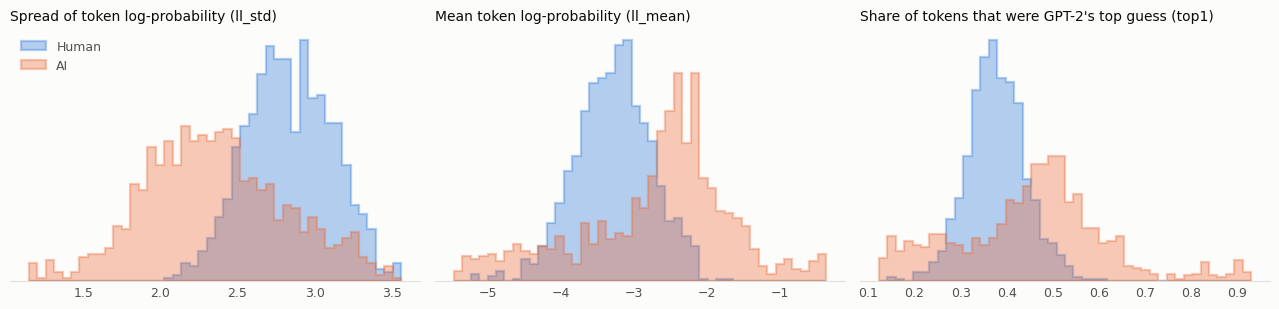

In [5]:
fig = plot_feature_by_class(F_va, y_va, ["ll_std", "ll_mean", "top1"],
                            ["Spread of token log-probability (ll_std)", "Mean token log-probability (ll_mean)",
                             "Share of tokens that were GPT-2's top guess (top1)"])
savefig(fig, "joling_lm_feature_hist");

## Step 2 · Classifiers on the 24 features
Two model families: logistic regression (one weight per feature) and gradient-boosted trees (can combine features).
Settings are chosen by 5-fold cross-validation **inside the 8,000 training rows**; the validation set is not used here.

In [6]:
grid = {f"logreg C={C}": (lambda C=C: lm_logreg(C)) for C in (0.1, 1.0, 10.0)}
grid.update({f"boost depth={d} lr={lr}": (lambda d=d, lr=lr: lm_boost(max_depth=d, learning_rate=lr))
             for d in (2, 3, 5) for lr in (0.03, 0.1)})
rows = []
for name, make in grid.items():
    cv = cross_val_auroc(make(), train_df["text"], y_tr)
    rows.append({"setting": name, "cv_auroc_mean": cv["cv_auroc_mean"], "cv_auroc_std": cv["cv_auroc_std"]})
cv_table = pd.DataFrame(rows)
cv_table.to_csv(RESULTS_DIR / "joling_lm_cv.csv", index=False)

best_lr = cv_table[cv_table.setting.str.startswith("logreg")].sort_values("cv_auroc_mean").iloc[-1]["setting"]
best_boost = cv_table[cv_table.setting.str.startswith("boost")].sort_values("cv_auroc_mean").iloc[-1]["setting"]
print("chosen:", best_lr, "|", best_boost)
cv_table.round(4)

chosen: logreg C=10.0 | boost depth=3 lr=0.1


,setting,cv_auroc_mean,cv_auroc_std
0,logreg C=0.1,0.9512,0.0073
1,logreg C=1.0,0.9528,0.0067
2,logreg C=10.0,0.9529,0.0065
3,boost depth=2 lr=0.03,0.9651,0.0040
4,boost depth=2 lr=0.1,0.9710,0.0041
5,boost depth=3 lr=0.03,0.9684,0.0041
6,boost depth=3 lr=0.1,0.9720,0.0035
7,boost depth=5 lr=0.03,0.9712,0.0034
8,boost depth=5 lr=0.1,0.9716,0.0034


## Step 3 · The four validation numbers
The same stress test as notebook `01`, for the two language-model classifiers and for Allen's tuned SVM.
`score_train=True` also scores each training row with the model that did not see its domain; Step 4 needs those.

In [7]:
domains = TopicDomains(k=8).fit(train_df["text"])
dom_tr, dom_va = domains.predict(train_df["text"]), domains.predict(val_df["text"])

MAKERS = {"lm_logreg": grid[best_lr], "lm_boost": grid[best_boost], "svm": lambda: make_model("robust_svm_tuned")}
summ, val_scores, train_unseen, train_auroc = {}, {}, {}, {}
for name, make in MAKERS.items():
    t0 = time.time()
    summ[name], _, preds = domain_stress_test(make, train_df, val_df, dom_tr, dom_va, verbose=False, score_train=True)
    train_unseen[name] = preds.attrs.pop("train_unseen")   # training rows, each scored by the model that did not see its domain
    val_scores[name] = preds
    train_auroc[name] = auroc(y_tr, predict_proba1(make().fit(train_df["text"], y_tr), train_df["text"]))
    print(f"{name}: {time.time() - t0:.0f}s")

# Keep every per-text score so later notebooks do not have to refit anything.
pd.concat([d.assign(model=m) for m, d in val_scores.items()]).to_csv(RESULTS_DIR / "joling_scores_val.csv", index=False)
pd.concat([d.assign(model=m) for m, d in train_unseen.items()]).to_csv(RESULTS_DIR / "joling_scores_train_unseen.csv", index=False)

alone = pd.DataFrame(summ).T[["val_auroc", "val_layout_removed", "unseen_domain_mean", "unseen_layout_removed_mean", "fit_seconds"]]
alone.insert(0, "train_auroc", pd.Series(train_auroc))
alone.round(4)

lm_logreg: 7s


lm_boost: 9s


svm: 294s


,train_auroc,val_auroc,val_layout_removed,unseen_domain_mean,unseen_layout_removed_mean,fit_seconds
lm_logreg,0.9542,0.9594,0.9594,0.9567,0.9567,0.5
lm_boost,0.9942,0.9794,0.9794,0.9761,0.9761,0.8
svm,1.0000,0.9786,0.9786,0.9328,0.9328,23.5


## Step 4 · Blend with Allen's SVM
Each model ranks the texts and we take a weighted average of the ranks (`src.evaluate.rank_average`, the same method
the team uses). The only choice is the weight of the language-model classifier.

A random split would favour the SVM, because the SVM is strongest on topics it has seen. So the weight is chosen
where it matters: on **training rows scored by models that never saw their domain**, with layout removed.
No validation label is used for this choice.

language-model classifier used in the blend: lm_boost
chosen weight of the language-model classifier: 0.6


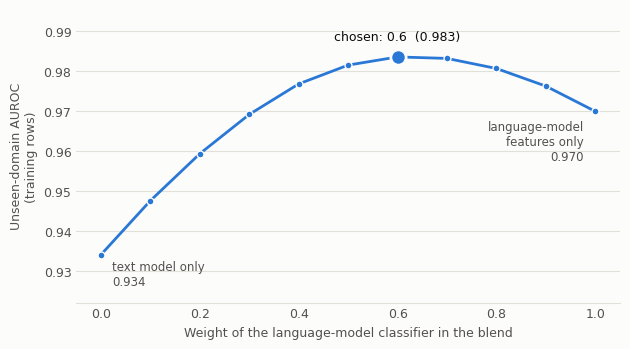

In [8]:
# Which language-model classifier goes into the blend? The one with the better cross-validation score on the training rows.
cv_best = cv_table.set_index("setting")["cv_auroc_mean"]
LM = "lm_boost" if cv_best[best_boost] >= cv_best[best_lr] else "lm_logreg"
print("language-model classifier used in the blend:", LM)
weights = np.round(np.arange(0, 1.01, 0.1), 1)
tu_svm, tu_lm = train_unseen["svm"], train_unseen[LM]
curve = [mean_auroc_by_domain(y_tr, blend_by_domain(tu_svm["p_unseen_layout_removed"], tu_lm["p_unseen"], dom_tr, w), dom_tr)
         for w in weights]
W = float(weights[int(np.argmax(curve))])
weight_table = pd.DataFrame({"lm_weight": weights, "train_unseen_auroc": curve})
weight_table.to_csv(RESULTS_DIR / "joling_blend_weights.csv", index=False)
print("chosen weight of the language-model classifier:", W)

fig = plot_weight_curve(weights, curve, W)
savefig(fig, "joling_blend_weight");

In [9]:
def blank_push(p, texts, push=0.1):
    # Allen's BlankLineBoost (robust_svm_tuned_blank): nudge up texts that use blank-line paragraph breaks.
    b = np.array([has_blank_line_breaks(t) for t in texts], dtype=float)
    return (np.asarray(p) + push * b) / (1 + push)


def four_numbers(std, flat, unseen, unseen_flat):
    return {"val_auroc": auroc(y_va, std), "val_layout_removed": auroc(y_va, flat),
            "unseen_domain_mean": mean_auroc_by_domain(y_va, unseen, dom_va),
            "unseen_layout_removed_mean": mean_auroc_by_domain(y_va, unseen_flat, dom_va)}


S, L = val_scores["svm"], val_scores[LM]
# With layout removed there are no blank lines left, so the push only applies to the unchanged text.
svm_blank = {"std": blank_push(S["p_standard"], val_df["text"]), "flat": S["p_layout_removed"].to_numpy(),
             "unseen": blank_push(S["p_unseen"], val_df["text"]), "unseen_flat": S["p_unseen_layout_removed"].to_numpy()}

table = pd.DataFrame({
    "svm (robust_svm_tuned)": four_numbers(S["p_standard"], S["p_layout_removed"], S["p_unseen"], S["p_unseen_layout_removed"]),
    "svm + blank-line boost": four_numbers(svm_blank["std"], svm_blank["flat"], svm_blank["unseen"], svm_blank["unseen_flat"]),
    "language-model classifier": four_numbers(L["p_standard"], L["p_layout_removed"], L["p_unseen"], L["p_unseen_layout_removed"]),
    f"blend: svm + LM (w={W})": four_numbers(
        blend(S["p_standard"], L["p_standard"], W), blend(S["p_layout_removed"], L["p_layout_removed"], W),
        blend_by_domain(S["p_unseen"], L["p_unseen"], dom_va, W),
        blend_by_domain(S["p_unseen_layout_removed"], L["p_unseen_layout_removed"], dom_va, W)),
    f"blend: svm + blank + LM (w={W})": four_numbers(
        blend(svm_blank["std"], L["p_standard"], W), blend(svm_blank["flat"], L["p_layout_removed"], W),
        blend_by_domain(svm_blank["unseen"], L["p_unseen"], dom_va, W),
        blend_by_domain(svm_blank["unseen_flat"], L["p_unseen_layout_removed"], dom_va, W)),
}).T.rename_axis("model").reset_index()
table.to_csv(RESULTS_DIR / "joling_lm_blend.csv", index=False)
for _, r in table.iterrows():
    log_result("joling_lm_blend_log", {"model": r["model"], "lm_weight": W, "lm": best_boost, "seed": SEED},
               {c: r[c] for c in table.columns[1:]})
print("rank correlation between the SVM and the language-model classifier on validation:",
      round(spearmanr(S["p_standard"], L["p_standard"]).statistic, 3))
table.round(4)

rank correlation between the SVM and the language-model classifier on validation: 0.76


,model,val_auroc,val_layout_removed,unseen_domain_mean,unseen_layout_removed_mean
0,svm (robust_svm_tuned),0.9786,0.9786,0.9328,0.9328
1,svm + blank-line boost,0.9905,0.9786,0.9690,0.9328
2,language-model classifier,0.9794,0.9794,0.9761,0.9761
3,blend: svm + LM (w=0.6),0.9934,0.9934,0.9866,0.9866
4,blend: svm + blank + LM (w=0.6),0.9949,0.9934,0.9914,0.9866


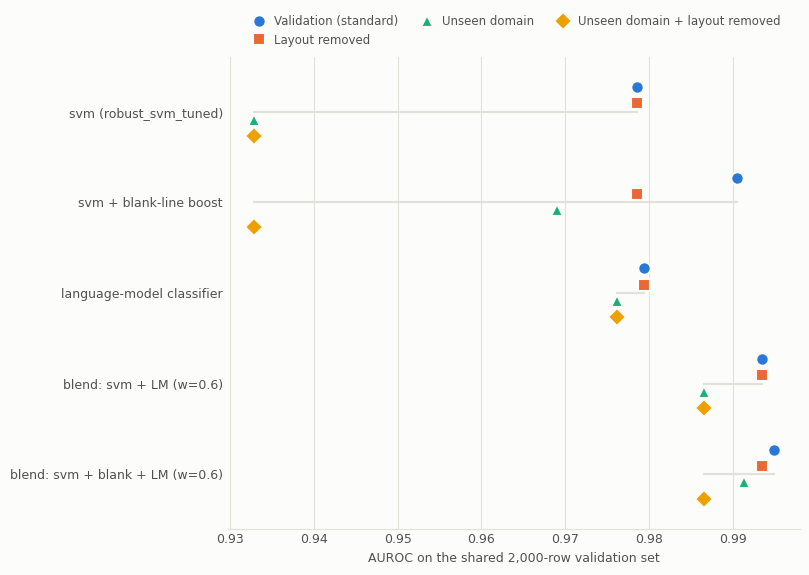

In [10]:
fig = plot_stress_summary(table)
savefig(fig, "joling_lm_blend_summary");

In [11]:
# Where does the gain come from? Unseen-domain AUROC per domain (layout removed).
by_dom = pd.DataFrame({
    "svm": [auroc(y_va[dom_va == d], S["p_unseen_layout_removed"][dom_va == d]) for d in range(domains.k)],
    "language-model": [auroc(y_va[dom_va == d], L["p_unseen"][dom_va == d]) for d in range(domains.k)],
    "blend": [auroc(y_va[dom_va == d], blend(S["p_unseen_layout_removed"][dom_va == d], L["p_unseen"][dom_va == d], W))
              for d in range(domains.k)],
}, index=domains.names_)
by_dom.to_csv(RESULTS_DIR / "joling_lm_blend_by_domain.csv")
by_dom.round(4)

,svm,language-model,blend
"d0: ve, like, just",0.8990,0.9786,0.9868
"d1: said, year, company",0.8863,0.9735,0.9800
"d2: properties, study, quantum",0.9304,0.9762,0.9827
"d3: pepper, cup, chopped",0.9862,0.9817,0.9938
"d4: film, movie, br",0.9089,0.9955,0.9902
"d5: segmentation, image, images",0.9497,0.9707,0.9860
"d6: sugar, cup, flour",0.9969,0.9653,0.9925
"d7: born, university, career",0.9052,0.9676,0.9809


## Step 5 · Train on all 10,000 labelled rows and write the Kaggle files
Same settings and the same blend weight as above; nothing is re-tuned. Three files, so the leaderboard can tell us
which part helps: the language-model classifier alone, the blend with the SVM, and the blend with the SVM + blank-line boost.

In [12]:
full_df = pd.concat([train_df, val_df], ignore_index=True)
lm_all = MAKERS[LM]().fit(full_df["text"], full_df["label"])
svm_all = make_model("robust_svm_tuned").fit(full_df["text"], full_df["label"])

t_lm = predict_proba1(lm_all, test_df["text"])
t_svm = predict_proba1(svm_all, test_df["text"])
t_svm_blank = blank_push(t_svm, test_df["text"])
t_blend, t_blend_blank = blend(t_svm, t_lm, W), blend(t_svm_blank, t_lm, W)

# Checks: does our SVM refit match Allen's saved test predictions, and how much do the two models agree on test?
saved = pd.read_csv(RESULTS_DIR / "preds_robust_svm_tuned.csv").query("split == 'test'").set_index("id").loc[test_df["id"], "prob"]
print("largest difference from Allen's saved SVM test predictions:", round(float(np.abs(saved.to_numpy() - t_svm).max()), 6))
print("rank correlation SVM vs language-model classifier:  validation", round(spearmanr(S["p_standard"], L["p_standard"]).statistic, 3),
      "| test", round(spearmanr(t_svm, t_lm).statistic, 3))
print("share of test texts scored above 0.5:  SVM", round(float((t_svm >= 0.5).mean()), 3), "| language-model", round(float((t_lm >= 0.5).mean()), 3))

# Prediction files in the team's format (validation scores from the 8,000-row model, test scores from the 10,000-row model).
save_predictions("joling_lm", val_df, L["p_standard"], test_df, t_lm)
save_predictions("joling_blend", val_df, blend(S["p_standard"], L["p_standard"], W), test_df, t_blend)
save_predictions("joling_blend_blank", val_df, blend(svm_blank["std"], L["p_standard"], W), test_df, t_blend_blank)

write_submission(test_df, t_lm, tag="joling_lm")
write_submission(test_df, t_blend, tag="joling_blend")
write_submission(test_df, t_blend_blank, tag="joling_blend_blank");

largest difference from Allen's saved SVM test predictions: 1e-06
rank correlation SVM vs language-model classifier:  validation 0.76 | test 0.673
share of test texts scored above 0.5:  SVM 0.366 | language-model 0.4
saved results/preds_joling_lm.csv
saved results/preds_joling_blend.csv
saved results/preds_joling_blend_blank.csv
wrote submissions/submission_20261110_183613_joling_lm.csv (3000 rows) - validated OK
wrote submissions/submission_20261110_183613_joling_blend.csv (3000 rows) - validated OK
wrote submissions/submission_20261110_183613_joling_blend_blank.csv (3000 rows) - validated OK


## What we learned
1. *How predictable* a text is carries almost as much signal as *which words* it uses (0.979 vs 0.979 on standard
   validation), and it transfers across topics far better (0.976 vs 0.933 on unseen domains).
2. No single feature is strong on its own; the best is the spread of token log-probabilities at 0.81. The histograms
   show why a tree model beats logistic regression (0.979 vs 0.959): AI texts form two groups, some far more predictable
   than human text and some less, so "more predictable = more AI" is not one straight line.
3. The SVM and the language-model classifier fail on different texts. The SVM is weakest on personal posts, news, film
   reviews and biographies when it has not seen them; the language-model classifier is weakest on recipes. The blend is
   at 0.98 or above in every domain.
4. Choosing the blend weight on unseen-domain training rows gives 0.6 to the language-model classifier. A random split
   would have favoured the SVM, which is the model that drops on new topics.

## Limits
- Training AUROC of the boosted model is 0.994 against 0.979 on validation, so it does fit the training rows somewhat.
- GPT-2 (2019) is an old, small model. Text from generators it resembles less, or AI text that was edited to look less
  regular, may not look "predictable" to it. Our validation data cannot test that; the Kaggle score will.
- Texts are cut at 512 tokens and layout is removed before scoring, so anything carried by layout is ignored on purpose.
- The unseen-domain test is still built from the training sources (see the limits in notebook `01`).

## Next
Upload the three files in `submissions/` and compare the public scores with Allen's 0.913. If the blend helps,
try a newer small language model for the features; if it does not, look at which test texts the two models disagree on.